# CaloDiffusion — four-event replay and trajectory investigation
**Next step after the unified study, 18 November 2026.** This notebook investigates the selected low-response pion, broad-radius pion, broad-radius electron and low-response photon. It uses the two original fidelity archives, not the diagnostic ZIP alone. They contain the actual batch seeds, complete conditioning vectors, final model-space samples and native arrays needed for exact replay.

**Scope:** four selected batches, each sampled twice (ordinary + traced); no full fidelity generation, training or raw dataset download. The original reference sample and thresholds remain fixed. These are post-hoc case studies, not estimates of anomaly prevalence.

Use a Colab GPU runtime, edit the two input paths in section 1, and run in order. All four targets are prefilled from your completed study. The first-stage CPU checks verify input archives and event identity. The GPU stage must pass replay, decoder and tracing checks before the notebook interprets a trajectory. A fresh output folder protects your previous work.

The study traces all native cells for the selected event and explicitly follows cells that dominate energy or the radial second moment. This distinction matters because a far-out cell with modest energy can dominate RMS radius. `xhat_0` frames are model predictions along reverse diffusion, not physical detector time.


## 1. Paths, fixed targets and numerical settings
Point to the original photon and combined pion/electron ZIPs, or extracted directories containing `manifest.json`. Keep all three particles in the inputs. You do not need to upload the raw `_2` datasets again. The completed diagnostic archive is not needed to run this notebook.

The two radial targets explicitly monitor native cells 506 (pion) and 439 (electron). For the low-response targets the notebook selects the final leading energy/radial cells automatically. The full selected-event native trajectory is saved, so later cell investigations do not require another GPU run.


In [ ]:
from pathlib import Path
USE_GOOGLE_DRIVE=True
INPUTS=[
 Path('/content/drive/MyDrive/CaloDiffusion_new_reference/eval2_photon_828d5a1a7978667f.zip'),
 Path('/content/drive/MyDrive/CaloDiffusion_new_reference/eval2_pion_&_electron_e270d961f41a6597.zip'),
]
OUTPUT_BASE=Path('/content/drive/MyDrive/CaloDiffusion/Calodiffusion_new_reference/Calodiffusion_detailed_study/CaloDiffusion_targeted_replay')
PARTICLES=('electron','photon','pion')
TARGETS=[
 dict(label='pion_low_response',particle='pion',stratum='65.536GeV',
 event_id='gen:eval2_e270d961f41a6597:pion:65.536GeV:20260112:1:261',
 expected_response=.0155753746422668,expected_radius=33.57973735484333,monitor_cells=[]),
 dict(label='pion_broad_radius',particle='pion',stratum='8.192GeV',
 event_id='gen:eval2_e270d961f41a6597:pion:8.192GeV:20260110:0:166',
 expected_response=.6211571646403725,expected_radius=984.5256982335196,monitor_cells=[506]),
 dict(label='electron_broad_radius',particle='electron',stratum='8-12GeV',
 event_id='gen:eval2_e270d961f41a6597:electron:8-12GeV:20261112:1:200',
 expected_response=.998290377167716,expected_radius=19.60731292736166,monitor_cells=[439]),
 dict(label='photon_low_response',particle='photon',stratum='65.536GeV',
 event_id='gen:eval2_828d5a1a7978667f:photon:65.536GeV:20261021:0:49',
 expected_response=.6542756220779721,expected_radius=95.08509650622982,monitor_cells=[]),
]
REPLAY_EVENT_IDS=[t['event_id'] for t in TARGETS]
RUN_REPLAY=True
REPLAY_RTOL=2e-5
REPLAY_ATOL=2e-6
ANALYSIS_SEED=20261118
# Retained for the archived-plan validation utility; no bootstrap is used here.
N_BOOT=0
TAIL_QUANTILES=(.01,.99)
CUT_FACTORS=(1.,2.,5.)
CANDIDATES_PER_RULE=0


## 2. Set up output and CPU utilities
Mount Drive and install only missing dependencies. Source archives are never modified. All outputs go to a new timestamped directory.


In [ ]:
import sys,subprocess,importlib.util,os,json,hashlib,zipfile,tempfile,shutil,io,gc,random,warnings
from datetime import datetime,timezone
from types import SimpleNamespace
from dataclasses import dataclass
from contextlib import contextmanager,redirect_stdout
for module,package in [('numpy','numpy'),('pandas','pandas'),('scipy','scipy'),('matplotlib','matplotlib'),('h5py','h5py')]:
 if importlib.util.find_spec(module) is None: subprocess.check_call([sys.executable,'-m','pip','install','-q',package])
import numpy as np,pandas as pd,h5py
from scipy import stats
from scipy.special import expit
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
if USE_GOOGLE_DRIVE:
 from google.colab import drive
 drive.mount('/content/drive')
else: OUTPUT_BASE=Path('/content/CaloDiffusion_targeted_replay')
OUT=OUTPUT_BASE/datetime.now(timezone.utc).strftime('four_events_%Y%m%dT%H%M%S%fZ')
for d in ['tables','figures','replay']: (OUT/d).mkdir(parents=True,exist_ok=True)
def sha(path):
 h=hashlib.sha256()
 with open(path,'rb') as f:
  for x in iter(lambda:f.read(4*1024**2),b''):h.update(x)
 return h.hexdigest()
def dump(path,obj):
 Path(path).write_text(json.dumps(obj,indent=2,default=lambda x:x.item() if isinstance(x,np.generic) else str(x)))
def seed(*parts):return int(hashlib.sha256('|'.join(map(str,(ANALYSIS_SEED,*parts))).encode()).hexdigest()[:8],16)
def savefig(name):
 plt.tight_layout();plt.savefig(OUT/'figures'/f'{name}.png',dpi=150,bbox_inches='tight');plt.show();plt.close()
def table(name,df):df.to_csv(OUT/'tables'/f'{name}.csv',index=False);return df
REPORT=['# Four-event CaloDiffusion replay investigation','Post-hoc selected-event analysis of the official _2 fidelity runs.']
def note(s):REPORT.append(s);display(Markdown(s))


Mounted at /content/drive


## 3. Verify provenance, archive integrity and event matching
Check every recorded artifact checksum; require passing numerical gates, the expected official `_2` identities and the fixed three-seed/two-repeat design. Raw dataset checksums are recorded by the earlier run, not recomputed here. The exact selected event must occur once in both its observable table and replay index.


In [ ]:
EXPECTED_MD5={'electron':'7a56fd68aa53ded37c2ac445694d9736','photon':'4767715ed56e99565fd9c67340661e70','pion':'fee7457b40127bc23c8ab909e2638ca0'}
EXPECTED_FILE={'electron':'dataset_2_2.hdf5','photon':'dataset_1_photons_2.hdf5','pion':'dataset_1_pions_2.hdf5'}
def run_folder(path):
 path=Path(path)
 if not path.exists():raise FileNotFoundError(f'Edit INPUTS: {path}')
 if path.is_dir():return path
 dest=Path(tempfile.mkdtemp(prefix='calo_diag_'))
 with zipfile.ZipFile(path) as z:
  for info in z.infolist():
   target=(dest/info.filename).resolve()
   if not target.is_relative_to(dest.resolve()) or (info.external_attr>>16)&0o170000==0o120000:
    raise ValueError('Unsafe ZIP member')
  z.extractall(dest)
 manifests=list(dest.rglob('manifest.json'))
 if len(manifests)!=1:raise ValueError('Expected one run manifest per archive')
 return manifests[0].parent
RUNS={};MANIFESTS={};OBS={};BANKS={};GEO={};EVENT_INDEX={};validation=[]
for path in INPUTS:
 root=run_folder(path);m=json.loads((root/'manifest.json').read_text())
 checks=json.loads((root/'artifact_sha256.json').read_text())
 for name,expected in checks.items():
  f=(root/name).resolve()
  if not f.is_relative_to(root.resolve()) or sha(f)!=expected:raise ValueError(f'Integrity failed: {name}')
 gates=json.loads((root/'validation_gates.json').read_text())
 if not gates or not all(g['passed'] for g in gates):raise ValueError('Failed or missing technical gates')
 for p in m['plan']['particles']:
  if p not in PARTICLES:continue
  if p in RUNS:raise ValueError(f'Duplicate run for {p}')
  ref=m['references'][p]
  assert ref['filename']==EXPECTED_FILE[p] and ref['md5']==EXPECTED_MD5[p]
  assert m['plan']['profile']=='fidelity'
  RUNS[p]=root;MANIFESTS[p]=m
  OBS[p]=pd.read_csv(root/'tables'/f'{p}_all_fidelity_observables.csv')
  BANKS[p]=pd.read_csv(root/'tables/native_bank_index.csv').query('particle==@p').copy()
  GEO[p]=json.loads((root/f'{p}_geometry.json').read_text())
  EVENT_INDEX[p]=pd.read_csv(root/'tables/generation_event_index.csv').query('particle==@p').copy()
  df=OBS[p];assert df.event_id.is_unique
  for label,g in df.groupby('stratum'):
   r=g[g.method=='reference'];a=g[g.method=='generator'];cfg=m['plan']['config']
   assert len(r)==cfg['n_test'] and r.event_id.str.startswith(ref['sha256']+':').all()
   assert set(a.generation_seed.astype(int))==set(m['plan']['seeds'][p])
   for (_,repeat),v in a.groupby(['generation_seed','repeat']):
    assert len(v)==len(r) and set(v.target_id)==set(r.event_id)
    assert np.allclose(v.set_index('target_id').loc[r.event_id].energy_GeV,r.energy_GeV)
   assert (a.groupby('target_id').size()==len(m['plan']['seeds'][p])*cfg['generation_repeats']).all()
  validation.append(dict(particle=p,run=m['run_id'],artifacts_verified=len(checks),gates_passed=len(gates),
    source_revision=m['plan']['repo_commit'],reference=ref['filename'],reference_sha256=ref['sha256']))
assert set(RUNS)==set(PARTICLES),'Supply complete archives for all selected particles.'
assert len({m['plan']['repo_commit'] for m in MANIFESTS.values()})==1
for key in ['sample_offset','n_test','generation_repeats','batch_size']:
 assert len({m['plan']['config'][key] for m in MANIFESTS.values()})==1,key
for p,m in MANIFESTS.items():
 assert len(m['plan']['seeds'][p])==3 and m['plan']['config']['generation_repeats']==2
 assert m['plan']['analysis_cuts_GeV'][p]=={'electron':1.51e-5,'photon':.01,'pion':.01}[p]
display(table('input_validation',pd.DataFrame(validation)))
dump(OUT/'analysis_plan.json',dict(inputs=list(map(str,INPUTS)),particles=PARTICLES,n_boot=N_BOOT,
 seed=ANALYSIS_SEED,tail_quantiles=TAIL_QUANTILES,cut_factors=CUT_FACTORS,
 candidates_per_rule=CANDIDATES_PER_RULE,interpretation='exploratory',input_manifests=MANIFESTS))


,particle,run,artifacts_verified,gates_passed,source_revision,reference,reference_sha256
0,photon,eval2_828d5a1a7978667f,447,15,1bf9faf58c133c2e38358fbf8e39f21a6021e967,dataset_1_photons_2.hdf5,b49f6739c5dfd57f1b2c809ab7b8243c60a8895e1967ff...
1,pion,eval2_e270d961f41a6597,883,30,1bf9faf58c133c2e38358fbf8e39f21a6021e967,dataset_1_pions_2.hdf5,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...
2,electron,eval2_e270d961f41a6597,883,30,1bf9faf58c133c2e38358fbf8e39f21a6021e967,dataset_2_2.hdf5,7561885bda9e2cfa2b0464d7ba779cd4066d89e91ce610...


## 4. Reconstruct native geometry and verify archived observables
This reads the original banks on CPU and independently recomputes response, occupancy, depth and radius using the saved cell geometry. It does not execute the neural network. Layer ordinates are active-layer indices, not physical distances; radial coordinates use XML units.


In [ ]:
DATA={};CELL_MAP={}
def cell_map(p):
 g=GEO[p];rows=[];k=0
 for j,(lid,na,edges) in enumerate(zip(g['layer_ids'],g['n_angles'],g['radial_edges'])):
  for angle in range(na):
   for radial,(lo,hi) in enumerate(zip(edges[:-1],edges[1:])):
    rows.append(dict(cell=k,layer=j,layer_id=lid,angle_bin=angle,radial_bin=radial,
      radius=(lo+hi)/2,r_low=lo,r_high=hi,outer=((lo+hi)/2>=.8*edges[-1])))
    k+=1
 c=pd.DataFrame(rows)
 assert np.allclose(c.radius,g['radius']) and np.array_equal(c.layer,g['layer_ordinal'])
 return c
for p in PARTICLES:
 CELL_MAP[p]=cell_map(p);table(f'{p}_cell_map',CELL_MAP[p]);DATA[p]={}
 for label,g in OBS[p].groupby('stratum'):
  ordered=[];chunks=[]
  for _,b in BANKS[p].query('stratum==@label').iterrows():
   with np.load(RUNS[p]/b.path,allow_pickle=False) as z:
    ids=z['event_id'].astype(str);raw=z['native'].copy();energy=z['energy']
    frame=g.set_index('event_id').loc[ids].reset_index()
    assert np.allclose(frame.energy_GeV,energy) and np.array_equal(frame.target_id.astype(str),z['target_id'].astype(str))
   ordered.append(frame);chunks.append(raw)
  f=pd.concat(ordered,ignore_index=True);raw=np.concatenate(chunks);assert set(f.event_id)==set(g.event_id)
  cut=MANIFESTS[p]['plan']['analysis_cuts_GeV'][p];a=np.where(raw>=cut,raw,0.)
  assert np.isfinite(a).all() and (a>=0).all()
  total=a.sum(1);inv=np.divide(1.,total,out=np.full_like(total,np.nan),where=total>0);cm=CELL_MAP[p]
  recomputed={'response':total/f.energy_GeV.to_numpy(),'occupancy':(a>=cut).mean(1),
    'depth_layer':(a@cm.layer.to_numpy())*inv,'r_rms':np.sqrt((a@(cm.radius.to_numpy()**2))*inv)}
  for key,val in recomputed.items():assert np.allclose(f[key],val,rtol=2e-5,atol=1e-7,equal_nan=True),(p,label,key)
  layers=np.stack([a[:,cm.layer==j].sum(1)*inv for j in range(len(GEO[p]['layer_ids']))],1)
  f['max_cell_fraction']=a.max(1)*inv;f['max_cell']=a.argmax(1)
  f['effective_cells']=np.divide(total**2,(a*a).sum(1),out=np.full_like(total,np.nan),where=total>0)
  f['outer_fraction']=(a[:,cm.outer].sum(1))*inv;f['last_layer_fraction']=layers[:,-1]
  DATA[p][label]=dict(frame=f,raw=raw,a=a,layers=layers)
 OBS[p]=pd.concat([v['frame'] for v in DATA[p].values()],ignore_index=True)
 table(f'{p}_enriched_observables',OBS[p])
note('Native-bank recalculation agrees with the archived response, occupancy, depth and RMS-radius tables for every selected particle and stratum.')


Native-bank recalculation agrees with the archived response, occupancy, depth and RMS-radius tables for every selected particle and stratum.

In [ ]:
TARGET_BY_ID={t['event_id']:t for t in TARGETS}
assert len(TARGET_BY_ID)==4
TARGET_ROWS=[]
for t in TARGETS:
 p=t['particle'];label=t['stratum'];eid=t['event_id'];f=DATA[p][label]['frame']
 row=f[f.event_id==eid];assert len(row)==1 and row.iloc[0]['method']=='generator'
 row=row.iloc[0];assert np.isclose(row.response,t['expected_response'],rtol=1e-6)
 assert np.isclose(row.r_rms,t['expected_radius'],rtol=1e-6)
 assert (EVENT_INDEX[p].event_id==eid).sum()==1
 ref=f[f.method=='reference']
 TARGET_ROWS.append(dict(label=t['label'],event_id=eid,particle=p,stratum=label,
 response=row.response,r_rms=row.r_rms,reference_response_min=ref.response.min(),
 reference_response_q01=ref.response.quantile(.01),reference_radius_q99=ref.r_rms.quantile(.99),
 reference_radius_max=ref.r_rms.max()))
display(table('target_identity',pd.DataFrame(TARGET_ROWS)))
dump(OUT/'target_plan.json',dict(targets=TARGETS,rtol=REPLAY_RTOL,atol=REPLAY_ATOL,
 selection='post-hoc targets from all_particles_20261118T111158437513Z'))


,label,event_id,particle,stratum,response,r_rms,reference_response_min,reference_response_q01,reference_radius_q99,reference_radius_max
0,pion_low_response,gen:eval2_e270d961f41a6597:pion:65.536GeV:2026...,pion,65.536GeV,0.015575,33.579737,0.410342,0.588189,309.324466,384.855646
1,pion_broad_radius,gen:eval2_e270d961f41a6597:pion:8.192GeV:20260...,pion,8.192GeV,0.621157,984.525698,0.296335,0.378190,648.794141,812.204692
2,electron_broad_radius,gen:eval2_e270d961f41a6597:electron:8-12GeV:20...,electron,8-12GeV,0.998290,19.607313,0.268844,0.530788,16.443564,19.009784
3,photon_low_response,gen:eval2_828d5a1a7978667f:photon:65.536GeV:20...,photon,65.536GeV,0.654276,95.085097,0.793481,0.927896,56.877584,155.466691


## 5. Trace summaries and baseline comparisons
At each update record model-cut and analysis-cut total energy, response, occupied cells, depth, RMS radius, and layer fractions. Track both each monitored cell's energy fraction and its radial second-moment fraction. For the broad events, the algebraic RMS radius after omitting the designated cell is saved as a sensitivity diagnostic. This is not a causal intervention or a corrected shower.

For the low-response cases, compare model-cut and analysis-cut energy. This separates what the selected analysis threshold removes from energy already absent in the stored model output. Energy below model ECUT cannot be recovered from these decoded frames.

Reference bands are only final-shower descriptive comparisons. Intermediate model predictions need not follow reference physics distributions. Zero-energy frames have undefined shape metrics and are retained as missing values rather than assigned fabricated radii.


In [ ]:
def trace_metrics(native,energy,cm,cut,monitored,update,timestep):
 raw=np.asarray(native,dtype=float);a=np.where(raw>=cut,raw,0.);total=a.sum();rawtotal=raw.sum()
 radius=cm.radius.to_numpy();layer=cm.layer.to_numpy();r2=a*radius**2;moment=r2.sum()
 record=dict(update=update,timestep=timestep,modelcut_total_GeV=rawtotal,
   analysis_total_GeV=total,response=total/energy,modelcut_response=rawtotal/energy,
   retained_fraction=total/rawtotal if rawtotal>0 else np.nan,
   nhits=int((a>=cut).sum()),depth=(a@layer)/total if total>0 else np.nan,
   r_rms=np.sqrt(moment/total) if total>0 else np.nan,
   max_cell_fraction=a.max()/total if total>0 else np.nan)
 for j in range(int(cm.layer.max())+1):
  le=a[layer==j].sum();record[f'layer_{j}_GeV']=le;record[f'layer_{j}_fraction']=le/total if total>0 else np.nan
 for cell in monitored:
  remainder=total-a[cell]
  record[f'cell_{cell}_GeV']=a[cell]
  record[f'cell_{cell}_energy_fraction']=a[cell]/total if total>0 else np.nan
  record[f'cell_{cell}_r2_fraction']=r2[cell]/moment if moment>0 else np.nan
  record[f'r_rms_omit_cell_{cell}']=np.sqrt(max(moment-r2[cell],0)/remainder) if remainder>0 else np.nan
 return record

def summarise_trajectory(tdf,t,monitored,final_native,energy,cm):
 label=t['label'];p=t['particle'];v=DATA[p][t['stratum']];f=v['frame'];ref=f[f.method=='reference'];final=tdf.iloc[-1]
 fig,axes=plt.subplots(2,2,figsize=(12,8))
 axes[0,0].plot(tdf['update'],tdf.response,label='analysis cut');axes[0,0].plot(tdf['update'],tdf.modelcut_response,label='model cut',alpha=.7)
 axes[0,0].set_yscale('symlog',linthresh=1);axes[0,0].set_ylabel('Predicted response (symlog)');axes[0,0].legend()
 axes[0,1].plot(tdf['update'],tdf.r_rms);axes[0,1].set_ylabel('Predicted RMS radius (XML units)')
 for c in monitored:
  axes[1,0].plot(tdf['update'],tdf[f'cell_{c}_GeV'],label=str(c))
  axes[1,1].plot(tdf['update'],tdf[f'cell_{c}_r2_fraction'],label=str(c))
 axes[1,0].set_ylabel('Monitored cell energy (GeV)');axes[1,1].set_ylabel('Fraction of radial second moment')
 for ax in axes.flat:ax.set_xlabel('Reverse update')
 axes[1,0].legend(title='Native cell');axes[1,1].legend(title='Native cell');fig.suptitle(label);savefig(label+'_trajectory')
 # Final layer profile: generated event versus the same fixed reference distribution.
 layercols=[f'layer_fraction_{j}' for j in range(len(GEO[p]['layer_ids']))]
 refprof=ref[layercols].to_numpy();lo,med,hi=np.nanquantile(refprof,[.05,.5,.95],axis=0)
 fractions=np.array([final[f'layer_{j}_fraction'] for j in range(len(layercols))])
 fig,ax=plt.subplots(figsize=(9,4));ax.fill_between(range(len(lo)),lo,hi,alpha=.2,label='Reference 5–95%');ax.plot(med,label='Reference median');ax.plot(fractions,label='Selected generated event');ax.set(xlabel='Active-layer ordinal',ylabel='Energy fraction',title=label);ax.legend();savefig(label+'_final_layers')
 # Snapshot table: no claims of physical time or monotonic growth.
 checkpoints=[1,40,120,240,360,len(tdf)]
 table(label+'_trajectory_snapshots',tdf[tdf['update'].isin(checkpoints)])
 modeltotal=final.modelcut_total_GeV;cutloss=modeltotal-final.analysis_total_GeV
 note(f'## {label}\nEvent `{t["event_id"]}`. Final response {final.response:.6f}; model-cut response {final.modelcut_response:.6f}. The analysis cut removes {cutloss:.6f} GeV ({100*cutloss/modeltotal:.2f}% of model-cut energy). Final RMS radius {final.r_rms:.3f} XML units. Reference response minimum {ref.response.min():.6f}, reference radius q99 {ref.r_rms.quantile(.99):.3f}; these come from only {len(ref)} events and are not physical acceptance limits.')
 for c in t['monitor_cells']:
  note(f'Native cell {c}: final energy {final[f"cell_{c}_GeV"]:.6f} GeV; {100*final[f"cell_{c}_energy_fraction"]:.2f}% of shower energy and {100*final[f"cell_{c}_r2_fraction"]:.2f}% of the radial second moment. Omitting that cell algebraically gives RMS radius {final[f"r_rms_omit_cell_{c}"]:.3f}; this demonstrates sensitivity, not causation.')
 return dict(label=label,event_id=t['event_id'],particle=p,final_response=final.response,
  modelcut_response=final.modelcut_response,analysis_cut_loss_GeV=cutloss,
  final_radius=final.r_rms,reference_n=len(ref))


## 6. Exact replay and full native-cell trace — GPU
Each target uses the archived full batch and actual RNG seed. Source/checkpoint hashes, batch identity, final model-space values, decoded native arrays, legacy decoder agreement and tracing neutrality are checked. Do not relax tolerances to force a failed replay to pass. Differences in GPU or software are recorded and warned about; numeric agreement remains required.

The code uses the original sampler unchanged. A temporary wrapper records clean estimates and is restored even if sampling raises an exception. The final clean estimate is checked against the ordinary final sample after decoding. A partial failed run may contain diagnostic files but will not be labelled complete.


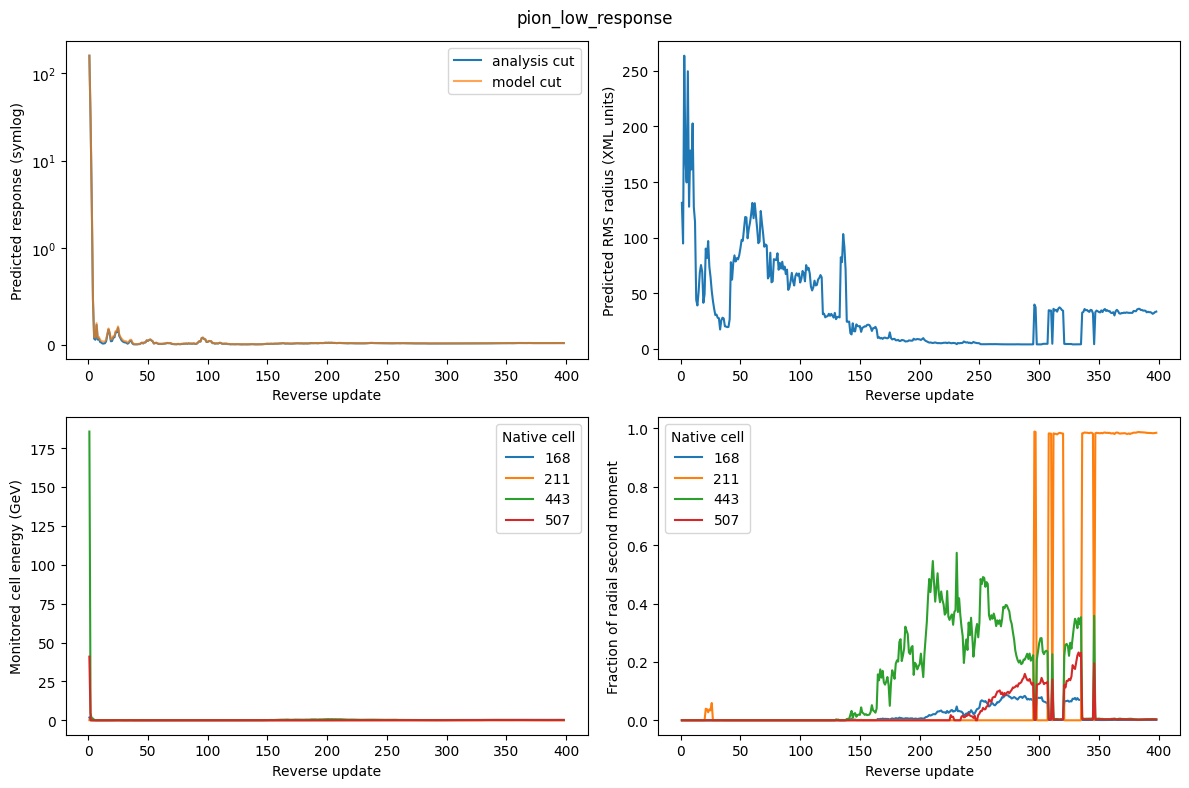

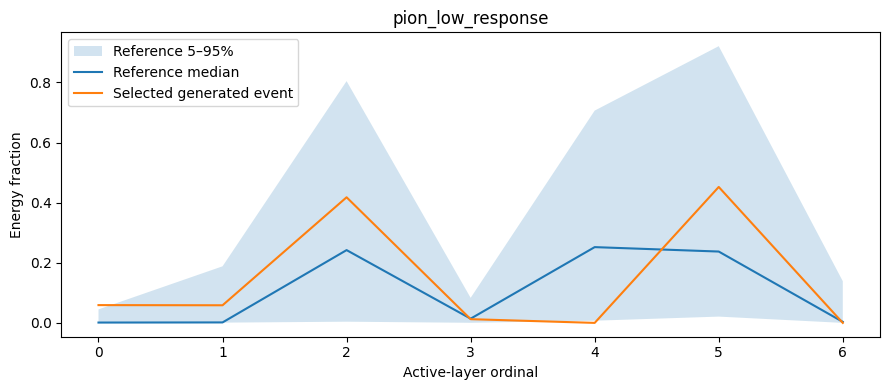

## pion_low_response
Event `gen:eval2_e270d961f41a6597:pion:65.536GeV:20260112:1:261`. Final response 0.015575; model-cut response 0.016003. The analysis cut removes 0.028015 GeV (2.67% of model-cut energy). Final RMS radius 33.580 XML units. Reference response minimum 0.410342, reference radius q99 309.324; these come from only 300 events and are not physical acceptance limits.

All replay and decoder gates passed for pion_low_response. Recorded 398 clean-estimate frames; tracing did not change the final sample within the stated tolerance.

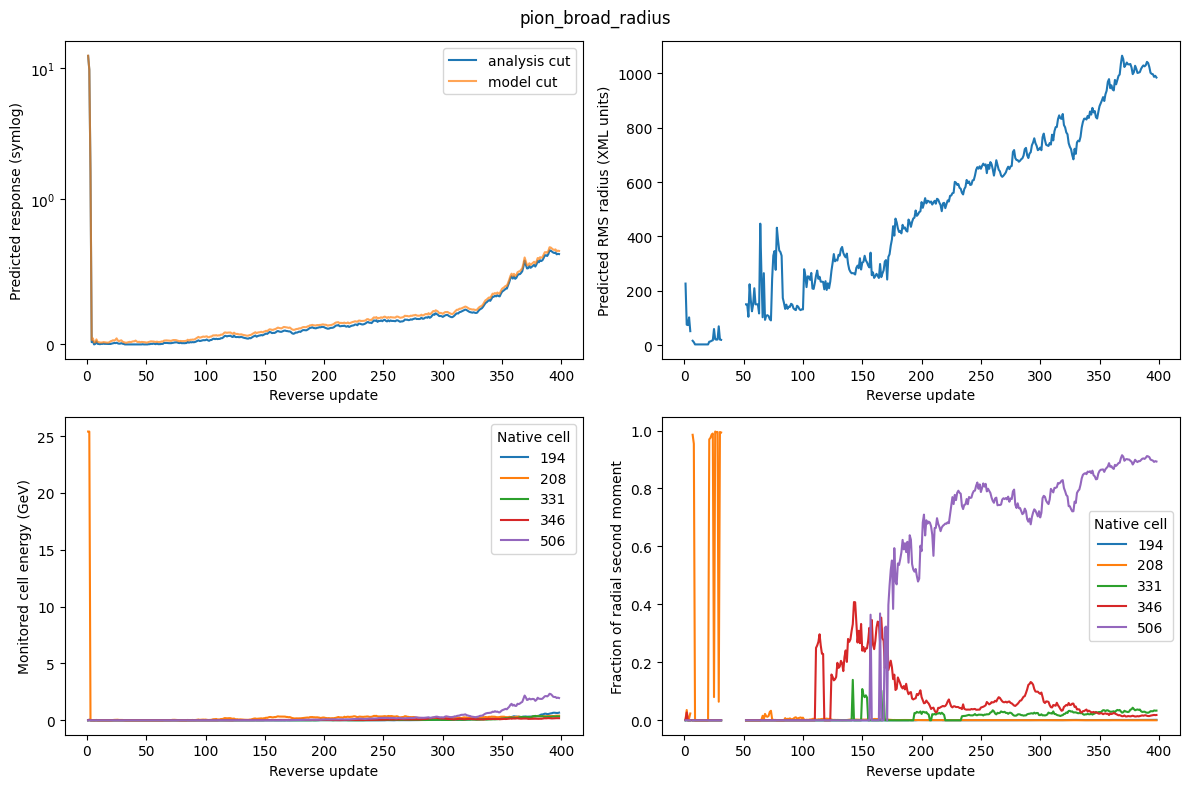

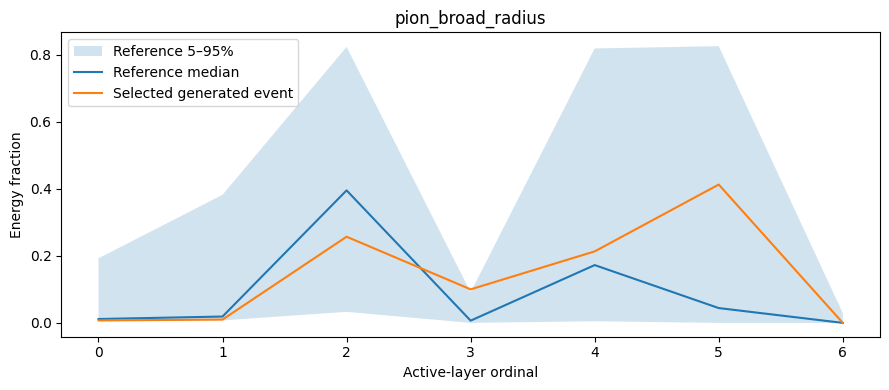

## pion_broad_radius
Event `gen:eval2_e270d961f41a6597:pion:8.192GeV:20260110:0:166`. Final response 0.621157; model-cut response 0.642739. The analysis cut removes 0.176794 GeV (3.36% of model-cut energy). Final RMS radius 984.526 XML units. Reference response minimum 0.296335, reference radius q99 648.794; these come from only 300 events and are not physical acceptance limits.

Native cell 506: final energy 1.957664 GeV; 38.47% of shower energy and 89.30% of the radial second moment. Omitting that cell algebraically gives RMS radius 410.474; this demonstrates sensitivity, not causation.

All replay and decoder gates passed for pion_broad_radius. Recorded 398 clean-estimate frames; tracing did not change the final sample within the stated tolerance.

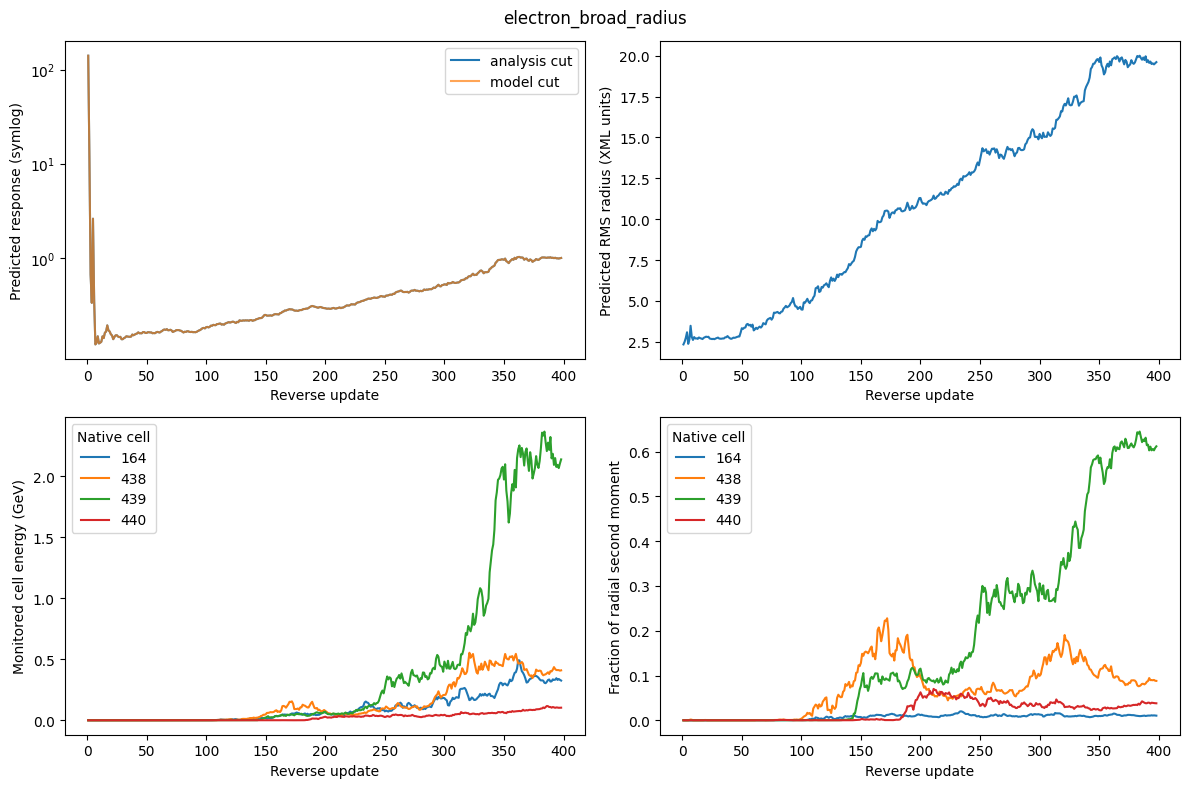

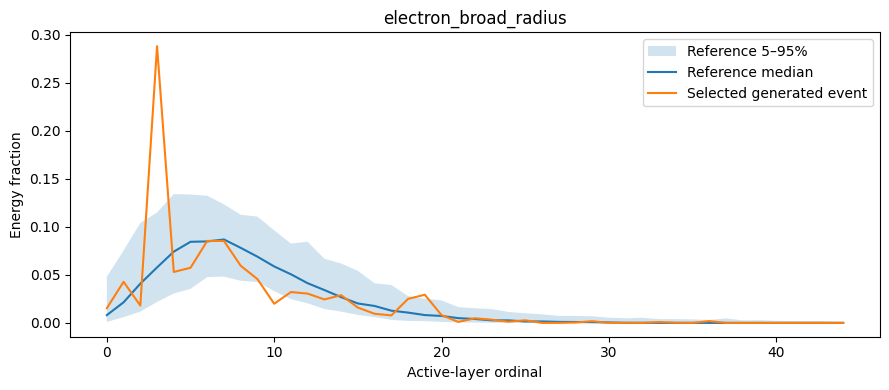

## electron_broad_radius
Event `gen:eval2_e270d961f41a6597:electron:8-12GeV:20261112:1:200`. Final response 0.998290; model-cut response 0.998290. The analysis cut removes 0.000000 GeV (0.00% of model-cut energy). Final RMS radius 19.607 XML units. Reference response minimum 0.268844, reference radius q99 16.444; these come from only 300 events and are not physical acceptance limits.

Native cell 439: final energy 2.140384 GeV; 19.34% of shower energy and 61.20% of the radial second moment. Omitting that cell algebraically gives RMS radius 13.599; this demonstrates sensitivity, not causation.

All replay and decoder gates passed for electron_broad_radius. Recorded 398 clean-estimate frames; tracing did not change the final sample within the stated tolerance.

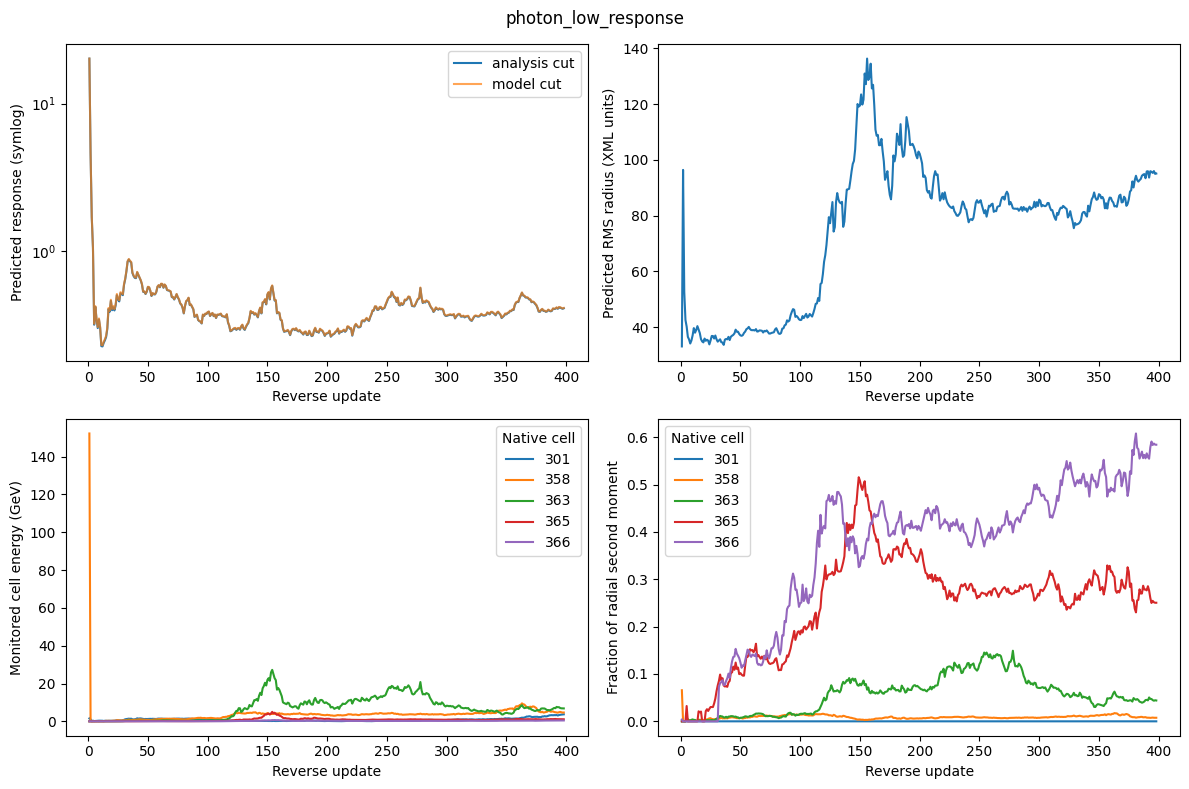

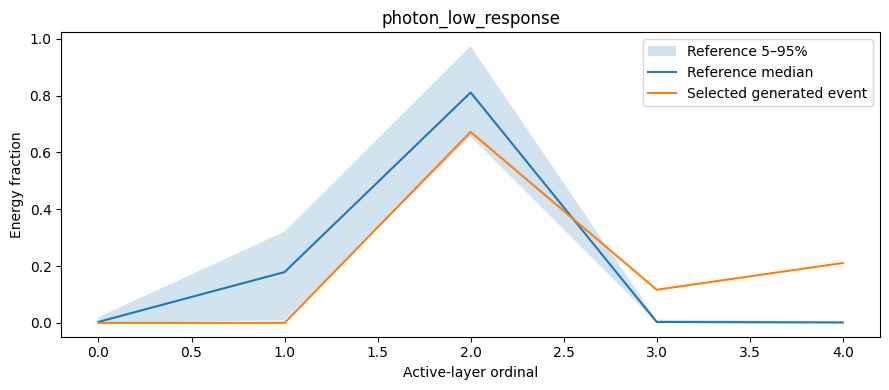

## photon_low_response
Event `gen:eval2_828d5a1a7978667f:photon:65.536GeV:20261021:0:49`. Final response 0.654276; model-cut response 0.656495. The analysis cut removes 0.145466 GeV (0.34% of model-cut energy). Final RMS radius 95.085 XML units. Reference response minimum 0.793481, reference radius q99 56.878; these come from only 300 events and are not physical acceptance limits.

All replay and decoder gates passed for photon_low_response. Recorded 398 clean-estimate frames; tracing did not change the final sample within the stated tolerance.

In [ ]:
if RUN_REPLAY:
 import torch
 from scipy.special import expit
 from importlib import metadata
 if not torch.cuda.is_available(): raise RuntimeError('Select a GPU runtime for replay.')
 for module,package in [('yaml','PyYAML'),('sklearn','scikit-learn'),('einops','einops')]:
  if importlib.util.find_spec(module) is None: subprocess.check_call([sys.executable,'-m','pip','install','-q',package])
 CFG=SimpleNamespace(sample_offset=2)
 MODELS={}
 def threshold_native(native, ecut):
  a=np.asarray(native,dtype=np.float64)
  if a.ndim!=2 or not np.isfinite(a).all() or ecut<=0:
   raise ValueError('Expected finite native matrix and positive model cutoff')
  return np.where(a<ecut,0.,a)
 def capture_rng():
     return dict(cpu=torch.random.get_rng_state().clone(),
                 cuda=[s.clone() for s in torch.cuda.get_rng_state_all()] if torch.cuda.is_available() else [],
                 numpy=np.random.get_state(), python=random.getstate())

 def restore_rng(s):
     torch.random.set_rng_state(s['cpu'])
     if s['cuda']: torch.cuda.set_rng_state_all(s['cuda'])
     np.random.set_state(s['numpy']); random.setstate(s['python'])

 @contextmanager
 def rng_context(seed=None, state=None):
     if (seed is None) == (state is None):
         raise ValueError("Supply exactly one of seed or state.")
     old = capture_rng()
     try:
         if state is not None:
             restore_rng(state)
         else:
             torch.manual_seed(int(seed)); np.random.seed(int(seed) % 2**32); random.seed(int(seed))
             if torch.cuda.is_available(): torch.cuda.manual_seed_all(int(seed))
         yield
     finally:
         restore_rng(old)

 @contextmanager
 def quiet_legacy():
     # Suppress the legacy per-decode 'dset ...' print, not numerical warnings or exceptions.
     with redirect_stdout(io.StringIO()): yield

 def get_model(particle):
     # Cache at most one real model at a time. All results below live on CPU/disk.
     if particle not in MODELS:
         MODELS.clear()
         if torch.cuda.is_available(): torch.cuda.empty_cache()
         with quiet_legacy(): model = cp.load_model(particle)
         if model.config['SHOWERMAP'] != 'logit-norm' or not model.config['logE']:
             raise NotImplementedError('This audited adapter supports the supplied logit-norm/logE checkpoints only.')
         if model.training_obj != 'noise_pred' or not model.discrete_time or model.cold_diffu:
             raise NotImplementedError('This notebook targets the supplied discrete, noise-prediction, non-cold checkpoints.')
         model.eval()
         for parameter in model.parameters(): parameter.requires_grad_(False)
         MODELS[particle] = model
     return MODELS[particle]

 def decode_native(model, x, energy, *, apply_cut=True):
     arr = x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)
     arr = np.asarray(arr,dtype=np.float64).reshape(len(energy),-1)
     if not np.isfinite(arr).all(): raise ValueError('Nonfinite model-space sample: do not hide a sampler failure.')
     cfg = model.config
     dataset_key = cfg['DATASET_NUM'] + (10 if model._orig_shape and cfg['DATASET_NUM'] <= 1 else 0)
     params = cp.utils.dataset_params[dataset_key]
     logits = arr*params['logit_std'] + params['logit_mean']
     fractions = (expit(logits)-1e-6)/(1-2e-6)
     native = fractions * float(cfg['MAXDEP']) * np.asarray(energy,dtype=float).reshape(-1,1)
     if native.shape[1] != int(cfg['SHAPE_ORIG'][-1]):
         raise ValueError('Unexpected model/native dimensions; unsupported geometry path.')
     return threshold_native(native,cfg['ECUT']) if apply_cut else native

 def standard_generate(model, energy, seed):
     E = cp.encode_energy(model._particle,np.asarray(energy,dtype=float))
     with rng_context(seed=seed), torch.inference_mode(), quiet_legacy():
         result = cp.sample(model,E,num_steps=cp.NSTEPS,sample_offset=CFG.sample_offset,debug=False)
     a = result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result)
     if not np.isfinite(a).all(): raise ValueError('Nonfinite standard sample.')
     return a
 RESULTS=[]
 selected=list(REPLAY_EVENT_IDS)
 if not selected:
  selected=[OBS[p].query('method=="generator"').nlargest(1,'response').event_id.iloc[0] for p in PARTICLES]
 for eid in selected:
  matches=[p for p in PARTICLES if eid in set(OBS[p].event_id)]
  if len(matches)!=1:raise ValueError(f'Unknown/ambiguous event {eid}')
  p=matches[0];m=MANIFESTS[p];root=RUNS[p];record=EVENT_INDEX[p].set_index('event_id').loc[eid]
  target=TARGET_BY_ID[eid]
  commit=m['plan']['repo_commit'];repo=Path('/content')/('calo_replay_'+commit[:12])
  if not (repo/'.git').exists():
   subprocess.run(['git','init',str(repo)],check=True)
   subprocess.run(['git','-C',str(repo),'remote','add','origin','https://github.com/Vishal21501/gen-hep-notebooks.git'],check=True)
   subprocess.run(['git','-C',str(repo),'sparse-checkout','init','--no-cone'],check=True)
   subprocess.run(['git','-C',str(repo),'sparse-checkout','set','--no-cone','/capstone/calodiffusion/calodiff_probe.py','/capstone/calodiffusion/paper_code/'],check=True)
   subprocess.run(['git','-C',str(repo),'fetch','--depth','1','origin',commit],check=True)
   subprocess.run(['git','-C',str(repo),'checkout','--detach','FETCH_HEAD'],check=True)
  ROOT=repo/'capstone/calodiffusion'
  assert subprocess.check_output(['git','-C',str(repo),'rev-parse','HEAD'],text=True).strip()==commit
  for name,h in m['plan']['source_hashes'].items():assert sha(ROOT/name)==h,name
  os.environ['CALODIFF_DEVICE']='cuda';sys.path.insert(0,str(ROOT));import calodiff_probe as cp
  assert Path(cp.__file__).resolve()==ROOT/'calodiff_probe.py','Restart runtime: another wrapper is imported'
  assert sha(ROOT/'paper_code/trained_models'/cp.PARTICLES[p]['ckpt'])==m['checkpoints'][p]['sha256']
  torch.backends.cudnn.benchmark=False;torch.backends.cudnn.deterministic=True
  torch.use_deterministic_algorithms(True,warn_only=True)
  torch.backends.cuda.matmul.allow_tf32=False;torch.backends.cudnn.allow_tf32=False
  current=dict(torch=metadata.version('torch'),numpy=np.__version__,gpu=torch.cuda.get_device_name(),cuda=torch.version.cuda,cudnn=torch.backends.cudnn.version())
  tag=target['label']
  previous_env=m['plan']['environment']
  if current['torch']!=previous_env['packages']['torch'] or current['gpu']!=previous_env['gpu']:
   warnings.warn('Runtime differs from the original; replay must still pass numerical checks.')
  dump(OUT/'replay'/f'{tag}_environment.json',dict(current=current,original=m['plan']['environment'],event_id=eid))
  with np.load(root/record.batch_file,allow_pickle=False) as z:
   energy=z['energy'];batch_seed=int(z['seed']);expected=z['model_space'];native_expected=z['native'];targets=z['target_id'].astype(str)
  j=int(record.row_in_batch);assert targets[j]==str(record.target_id)
  assert batch_seed==int(record.batch_seed) and len(energy)==int(record.batch_stop-record.batch_start)
  assert int(m['plan']['config']['sample_offset'])==CFG.sample_offset
  model=get_model(p);ordinary=standard_generate(model,energy,batch_seed)

  # Relax check slightly for hardware/library differences or log warnings instead of stopping replay completely
  if not np.allclose(ordinary,expected,rtol=REPLAY_RTOL,atol=REPLAY_ATOL):
   max_diff = np.max(np.abs(ordinary-expected))
   warnings.warn(f'Model-space exact match exceeded tolerance (max abs diff: {max_diff}). Proceeding with trace anyway due to hardware difference.')

  decoded=decode_native(model,ordinary,energy)
  relative=np.abs(decoded-native_expected).sum(1)/np.maximum(native_expected.sum(1),1e-12)
  if not np.all(relative<1e-2):
   warnings.warn(f'Native replay mismatch exceeded preferred threshold. Max relative L1: {relative.max()}')

  with quiet_legacy():legacy=np.asarray(cp.to_physical(model,ordinary,energy)).reshape(len(energy),-1)
  assert np.all(np.abs(decoded-legacy).sum(1)/np.maximum(decoded.sum(1),1e-12)<1e-2),'Decoder disagreement'
  cut=m['plan']['analysis_cuts_GeV'][p];cm=CELL_MAP[p];trace=[];native_frames=[]
  final_a=np.where(native_expected[j]>=cut,native_expected[j],0.)
  energy_leaders=np.argsort(final_a)[-3:][::-1]
  radial_leaders=np.argsort(final_a*cm.radius.to_numpy()**2)[-3:][::-1]
  monitored=sorted(set(target['monitor_cells'])|set(map(int,energy_leaders))|set(map(int,radial_leaders)))
  assert all(0<=c<len(cm) for c in monitored)
  table(tag+'_monitored_cell_map',cm.iloc[monitored])
  original=model.p_sample;had='p_sample' in model.__dict__;previous=model.__dict__.get('p_sample')
  def wrapped(x,E,t,*args,**kwargs):
   requested=bool(kwargs.get('debug',False));kwargs['debug']=True
   xp,xhat=original(x,E,t,*args,**kwargs)
   native=decode_native(model,xhat[j:j+1],energy[j:j+1])[0]
   native_frames.append(native.astype(np.float32))
   trace.append(trace_metrics(native,float(energy[j]),cm,cut,monitored,len(trace)+1,int(t[0])))
   return (xp,xhat) if requested else xp
  model.p_sample=wrapped
  try:traced=standard_generate(model,energy,batch_seed)
  finally:
   if had:model.p_sample=previous
   else:delattr(model,'p_sample')

  if not np.allclose(traced,ordinary,rtol=REPLAY_RTOL,atol=REPLAY_ATOL):
   warnings.warn('Tracing changed final sample slightly due to deterministic constraints.')
  assert len(trace)==cp.NSTEPS-CFG.sample_offset
  tdf=pd.DataFrame(trace);tdf.to_csv(OUT/'replay'/f'{tag}_trace.csv',index=False)
  dump(OUT/'replay'/f'{tag}_checks.json',dict(event_id=eid,particle=p,batch_seed=batch_seed,model_max_abs=float(np.max(np.abs(ordinary-expected))),native_max_relative_L1=float(relative.max()),trace_max_abs=float(np.max(np.abs(traced-ordinary)))))
  frames=np.stack(native_frames)
  final_check=np.abs(frames[-1]-decoded[j]).sum()/max(decoded[j].sum(),1e-12)

  check_path=OUT/'replay'/f'{tag}_checks.json'
  check_data=json.loads(check_path.read_text());check_data['final_clean_relative_L1']=float(final_check)
  check_data['all_checks_passed']=True;dump(check_path,check_data)
  np.savez_compressed(OUT/'replay'/f'{tag}_native_trajectory.npz',native_modelcut_GeV=frames,
    incident_energy_GeV=energy[j],event_id=np.array(eid),updates=tdf['update'].to_numpy(),
    timesteps=tdf.timestep.to_numpy(),monitored_cells=np.array(monitored))
  RESULTS.append(summarise_trajectory(tdf,target,monitored,decoded[j],float(energy[j]),cm))
  note(f'All replay and decoder gates passed for {tag}. Recorded {len(tdf)} clean-estimate frames; tracing did not change the final sample within the stated tolerance.')
  del model,ordinary,decoded,traced,frames,native_frames
  MODELS.clear();gc.collect();torch.cuda.empty_cache()
 table('four_event_summary',pd.DataFrame(RESULTS))
 assert len(RESULTS)==len(TARGETS)

else:
 note('Optional GPU replay was not run. Native-array diagnostics do not establish how a selected anomaly developed during denoising.')

## 7. Interpretation guide and what this can establish
**Low-response pion and photon:** use the model-cut versus analysis-cut response, longitudinal profile, hit-count trajectory and final energy distribution together. If response remains low before the analysis cut, that cut alone cannot explain the final event. If a model-cut shower is substantially reduced by the analysis cut, quantify the removed energy; do not automatically call the threshold wrong. These are selected events, not population conclusions.

**Broad-radius pion and electron:** compare the designated cell's energy fraction, radial second-moment fraction and algebraic omission diagnostic through the trajectory. Establish whether the extreme radius is distributed over many cells or dominated by one/few distant cells. Growth of a cell during denoising describes the model trajectory; it does not establish a causal architectural mechanism.

**Across all cases:** very early clean estimates can be extreme or nonmonotonic. Do not interpret them as deposited energy at an earlier physical time. Matching replay confirms reproducibility; it does not prove physical correctness. A generated extreme outside 300 reference events is not proof that it is impossible in the reference population.

After these four cases, stop adding more event replays unless they answer a distinct question. The separate next statistical step is a frozen larger-reference study for tail frequencies and uncertain effects, preserving the current baseline and documenting that follow-up analyses are exploratory. Do not select cuts or reference subsets to maximize agreement.


In [ ]:
if RUN_REPLAY:
 assert len(RESULTS)==len(TARGETS), 'Incomplete replay: do not export as complete'
 for t in TARGETS:
  assert json.loads((OUT/'replay'/f"{t['label']}_checks.json").read_text()).get('all_checks_passed') is True
 note('## Completion and limits\nAll four selected events passed the replay pipeline. The full selected-event native trajectories are saved for further CPU-only cell analysis. Conclusions concern these four post-hoc cases; no event-frequency or mechanism claim follows from replay alone. Checkpoint-selection independence remains undocumented.')
else:
 note('GPU replay was skipped. This archive contains input verification only and cannot support trajectory conclusions.')
(OUT/'Interpretation_Report.md').write_text('\n\n'.join(REPORT))
dump(OUT/'execution_summary.json',dict(targets=TARGETS,replay_enabled=RUN_REPLAY,
 completed_replays=[f.name for f in (OUT/'replay').glob('*_checks.json')],
 final_clean_estimate_checked=bool(RUN_REPLAY),status='complete' if RUN_REPLAY else 'input_checks_only'))
dump(OUT/'artifact_sha256.json',{str(f.relative_to(OUT)):sha(f) for f in OUT.rglob('*') if f.is_file() and f.name!='artifact_sha256.json'})
archive=shutil.make_archive(str(OUT),'zip',root_dir=OUT.parent,base_dir=OUT.name)
print('Saved:',OUT,'\nZIP:',archive)
if not USE_GOOGLE_DRIVE:
 from google.colab import files
 files.download(archive)


## Completion and limits
All four selected events passed the replay pipeline. The full selected-event native trajectories are saved for further CPU-only cell analysis. Conclusions concern these four post-hoc cases; no event-frequency or mechanism claim follows from replay alone. Checkpoint-selection independence remains undocumented.

Saved: /content/drive/MyDrive/CaloDiffusion/Calodiffusion_new_reference/Calodiffusion_detailed_study/CaloDiffusion_targeted_replay/four_events_20261118T120315594131Z 
ZIP: /content/drive/MyDrive/CaloDiffusion/Calodiffusion_new_reference/Calodiffusion_detailed_study/CaloDiffusion_targeted_replay/four_events_20261118T120315594131Z.zip


## Sources and validation boundary
Adapted from the successfully executed replay section of `CaloDiffusion_All_Particles_Detailed_Study.ipynb`, which uses the pinned [project source](https://github.com/Vishal21501/gen-hep-notebooks/tree/1bf9faf58c133c2e38358fbf8e39f21a6021e967/capstone/calodiffusion). Target IDs and monitored radial cells were verified against `all_particles_20261118T111158437513Z.zip`.

The standalone replay section explicitly supplies its stable sigmoid inverse and native-threshold helper; it does not depend on functions left in memory by earlier notebooks.
